In [97]:
 %pip install spacy

Note: you may need to restart the kernel to use updated packages.


In [197]:
%pip install scikit-plot 


Note: you may need to restart the kernel to use updated packages.


In [200]:
%pip install --upgrade scikit-plot

Note: you may need to restart the kernel to use updated packages.


In [201]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import re
import string
from wordcloud import WordCloud
from collections import Counter

import warnings
warnings.filterwarnings('ignore')

from nltk import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from scikitplot.metrics import plot_confusion_matrix, plot_roc

ImportError: cannot import name 'interp' from 'scipy' (C:\Users\admin\anaconda3\Lib\site-packages\scipy\__init__.py)

In [66]:
import numpy as np
import pandas as pd
import re
import nltk
import spacy
import string
pd.options.mode.chained_assignment = None

In [231]:
full_df = pd.read_csv("SPAM text message 20170820 - Data.csv", nrows=3000)
full_df

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
2995,ham,"No idea, I guess we'll work that out an hour a..."
2996,ham,Mm not entirely sure i understood that text bu...
2997,ham,They released vday shirts and when u put it on...
2998,ham,Don know..he is watching film in computer..


In [233]:
print(full_df.shape)

(3000, 2)


In [235]:
full_df.isnull().sum()

Category    0
Message     0
dtype: int64

In [237]:
df = full_df[["Message"]]
df["Message"] = df["Message"].astype(str)
full_df

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
2995,ham,"No idea, I guess we'll work that out an hour a..."
2996,ham,Mm not entirely sure i understood that text bu...
2997,ham,They released vday shirts and when u put it on...
2998,ham,Don know..he is watching film in computer..


In [239]:
full_df['Category'].value_counts()

Category
ham     2591
spam     409
Name: count, dtype: int64

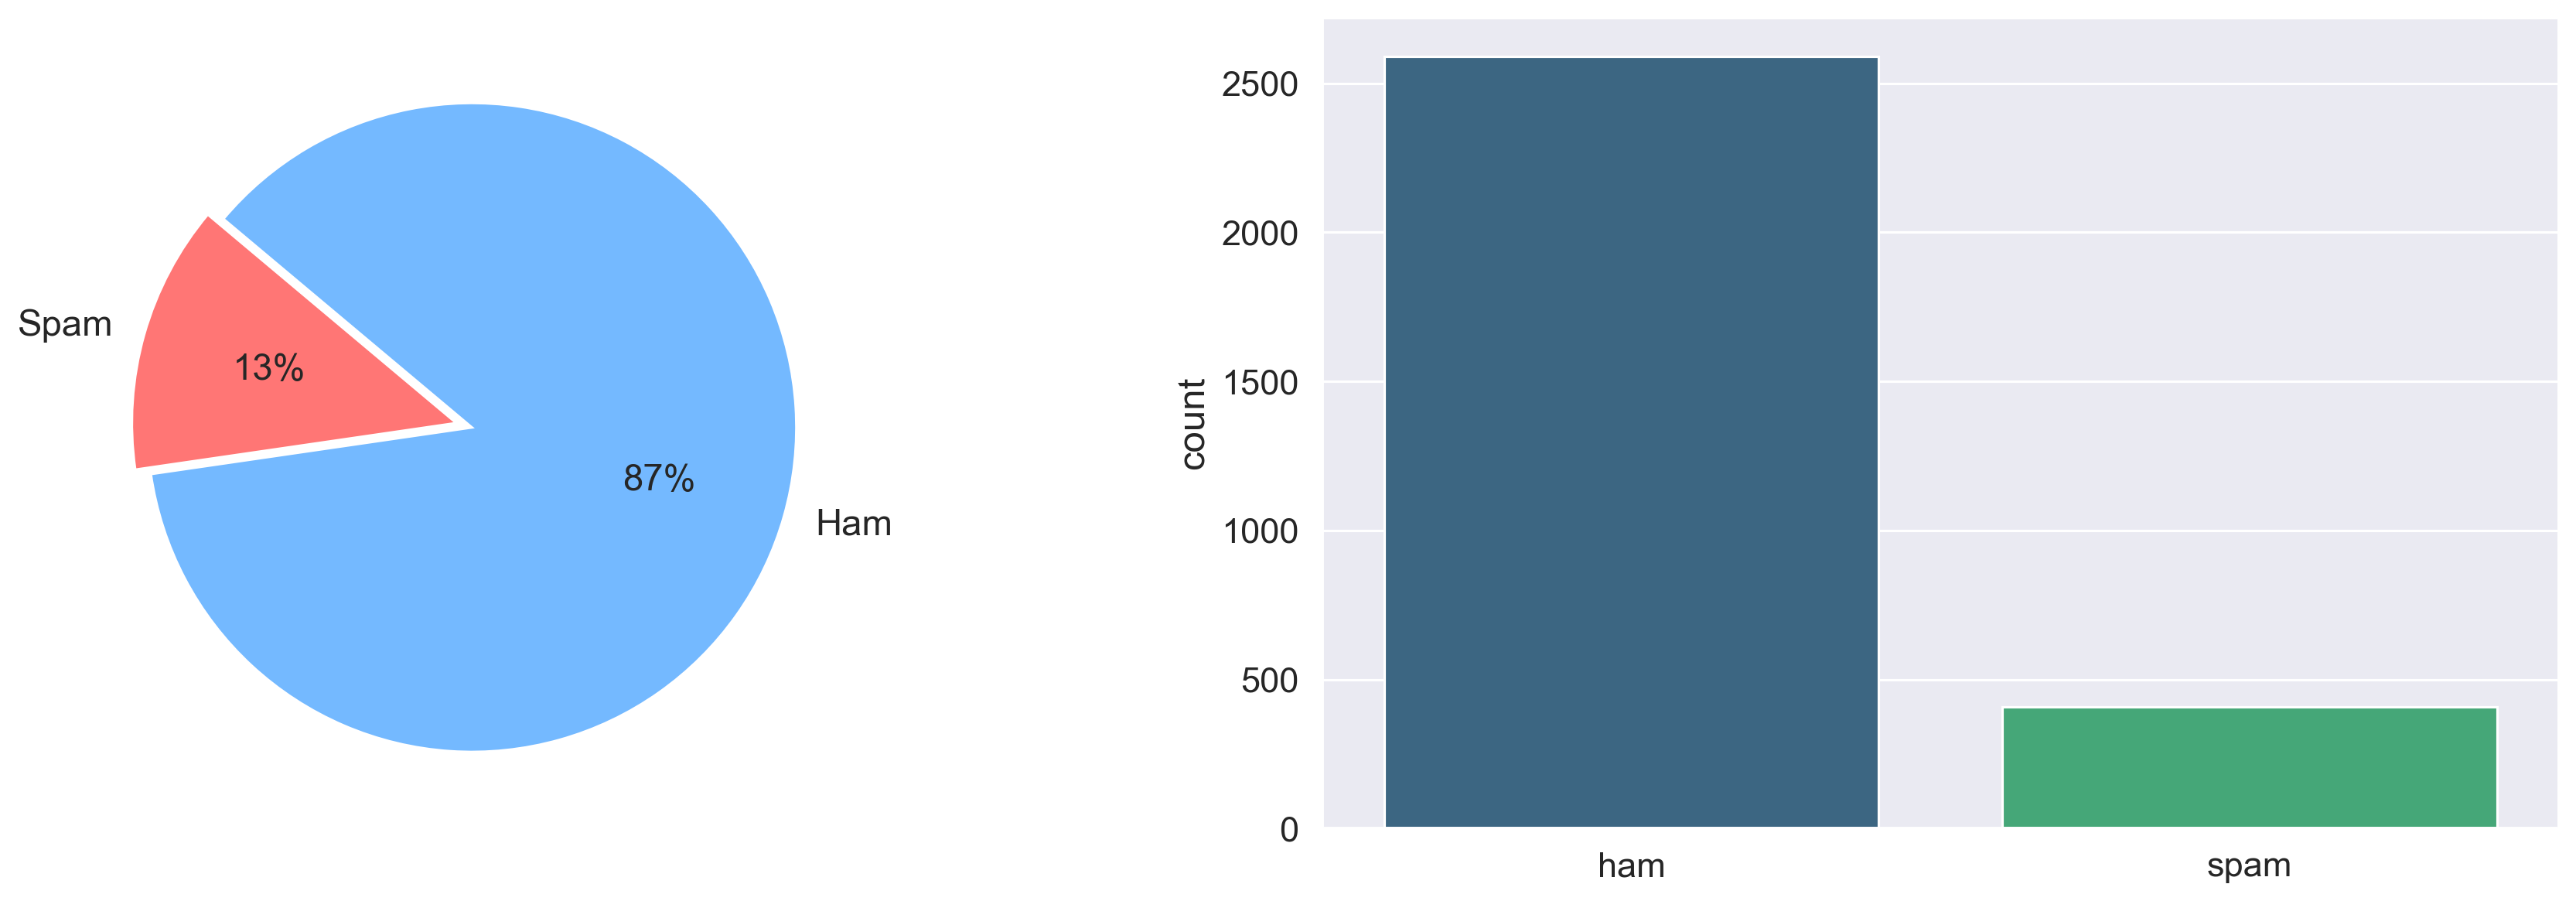

In [241]:
labels = ['Spam', 'Ham']
sizes = [747, 4825]
custom_colours = ['#ff7675', '#74b9ff']

plt.figure(figsize=(20, 6), dpi=227)
plt.subplot(1, 2, 1)
plt.pie(sizes, labels = labels, textprops={'fontsize': 15}, startangle=140, 
       autopct='%1.0f%%', colors=custom_colours, explode=[0, 0.05])

plt.subplot(1, 2, 2)
sns.barplot(x = full_df['Category'].unique(), y = full_df['Category'].value_counts(), palette= 'viridis')

plt.show()

### Feature Engineering


In [243]:
full_df['Total Words'] = full_df['Message'].apply(lambda x: len(x.split()))

def count_total_words(text):
    char = 0
    for word in text.split():
        char += len(word)
    return char

full_df['Total Chars'] = full_df["Message"].apply(count_total_words)

In [245]:
full_df.head()

,Category,Message,Total Words,Total Chars
0,ham,"Go until jurong point, crazy.. Available only ...",20,92
1,ham,Ok lar... Joking wif u oni...,6,24
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,28,128
3,ham,U dun say so early hor... U c already then say...,11,39
4,ham,"Nah I don't think he goes to usf, he lives aro...",13,49


In [247]:
df["message_lower"] = df["Message"].str.lower()
df.head()

,Message,message_lower
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."


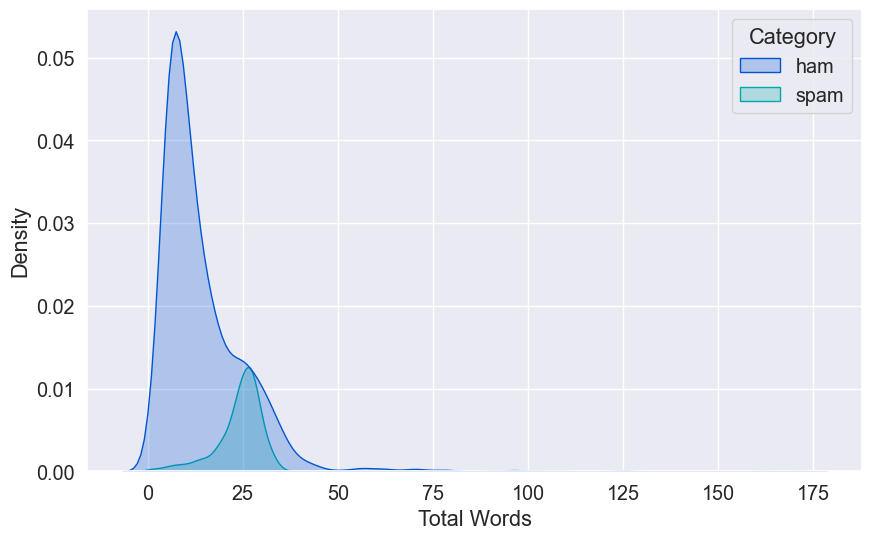

In [249]:
plt.figure(figsize = (10, 6))
sns.kdeplot(x = full_df['Total Words'], hue= full_df['Category'], palette= 'winter', shade = True)
plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_14416\1010853494.py:2: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x = full_df['Total Chars'], hue= full_df['Category'], palette= 'winter', shade = True)


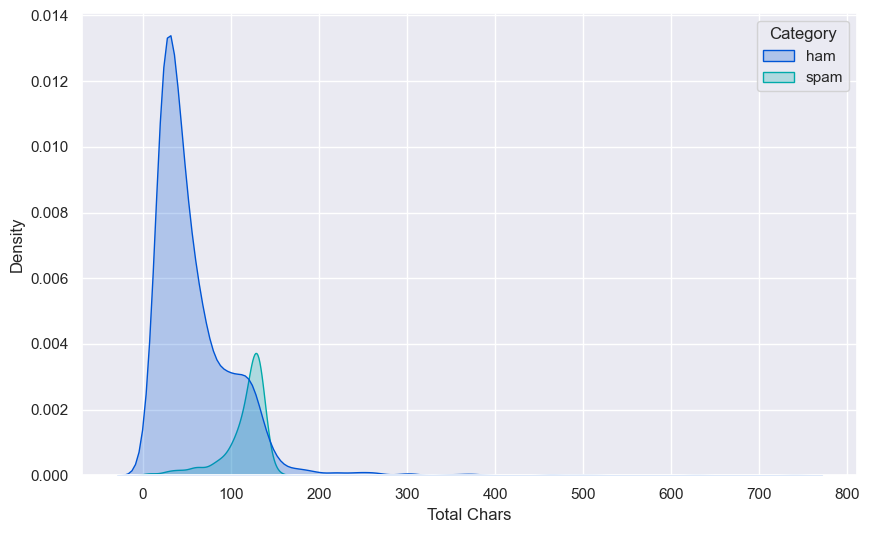

In [127]:
plt.figure(figsize = (10, 6))
sns.kdeplot(x = full_df['Total Chars'], hue= full_df['Category'], palette= 'winter', shade = True)
plt.show()

#### One thing we can conclude here is that more the number of words in a text, there are more chances of it being spam

### Text Preprocessing

### Lower Casing

In [251]:
def convert_lowercase(text):
    text = text.lower()
    return text

full_df['Message'] = full_df['Message'].apply(convert_lowercase)

In [253]:
full_df.head()

,Category,Message,Total Words,Total Chars
0,ham,"go until jurong point, crazy.. available only ...",20,92
1,ham,ok lar... joking wif u oni...,6,24
2,spam,free entry in 2 a wkly comp to win fa cup fina...,28,128
3,ham,u dun say so early hor... u c already then say...,11,39
4,ham,"nah i don't think he goes to usf, he lives aro...",13,49


### Remove Punctuation

In [255]:

PUNCT_TO_REMOVE = string.punctuation
def remove_punctuation(text):
    """custom function to remove the punctuation"""
    return text.translate(str.maketrans('', '', PUNCT_TO_REMOVE))

full_df["Message"] = full_df["Message"].apply(lambda text: remove_punctuation(text))
full_df.head(50)

,Category,Message,Total Words,Total Chars
0,ham,go until jurong point crazy available only in ...,20,92
1,ham,ok lar joking wif u oni,6,24
2,spam,free entry in 2 a wkly comp to win fa cup fina...,28,128
3,ham,u dun say so early hor u c already then say,11,39
4,ham,nah i dont think he goes to usf he lives aroun...,13,49
5,spam,freemsg hey there darling its been 3 weeks now...,32,116
6,ham,even my brother is not like to speak with me t...,16,62
7,ham,as per your request melle melle oru minnaminun...,26,135
8,spam,winner as a valued network customer you have b...,26,132
9,spam,had your mobile 11 months or more u r entitled...,29,126


### Remove URLs

In [257]:
def remove_url(text):
    re_url = re.compile('https?://\S+|www\.\S+')
    return re_url.sub('', text)

full_df['Message'] = full_df['Message'].apply(remove_url)

### Remove StopWords

In [259]:
 import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [261]:
from nltk.corpus import stopwords
", ".join(stopwords.words('english'))

"a, about, above, after, again, against, ain, all, am, an, and, any, are, aren, aren't, as, at, be, because, been, before, being, below, between, both, but, by, can, couldn, couldn't, d, did, didn, didn't, do, does, doesn, doesn't, doing, don, don't, down, during, each, few, for, from, further, had, hadn, hadn't, has, hasn, hasn't, have, haven, haven't, having, he, he'd, he'll, her, here, hers, herself, he's, him, himself, his, how, i, i'd, if, i'll, i'm, in, into, is, isn, isn't, it, it'd, it'll, it's, its, itself, i've, just, ll, m, ma, me, mightn, mightn't, more, most, mustn, mustn't, my, myself, needn, needn't, no, nor, not, now, o, of, off, on, once, only, or, other, our, ours, ourselves, out, over, own, re, s, same, shan, shan't, she, she'd, she'll, she's, should, shouldn, shouldn't, should've, so, some, such, t, than, that, that'll, the, their, theirs, them, themselves, then, there, these, they, they'd, they'll, they're, they've, this, those, through, to, too, under, until, up, 

In [263]:
STOPWORDS = set(stopwords.words('english'))
def remove_stopwords(text):
    """custom function to remove the stopwords"""
    return " ".join([word for word in str(text).split() if word not in STOPWORDS])

full_df["Message"] = full_df["Message"].apply(lambda text: remove_stopwords(text))
full_df.head()

,Category,Message,Total Words,Total Chars
0,ham,go jurong point crazy available bugis n great ...,20,92
1,ham,ok lar joking wif u oni,6,24
2,spam,free entry 2 wkly comp win fa cup final tkts 2...,28,128
3,ham,u dun say early hor u c already say,11,39
4,ham,nah dont think goes usf lives around though,13,49


In [265]:
from collections import Counter
cnt = Counter()
for text in full_df["Message"].values:
    for word in text.split():
        cnt[word] += 1
        
cnt.most_common(10)

[('u', 596),
 ('call', 298),
 ('2', 258),
 ('im', 240),
 ('ur', 220),
 ('get', 198),
 ('dont', 171),
 ('ok', 158),
 ('4', 158),
 ('go', 151)]

In [267]:
FREQWORDS = set([w for (w, wc) in cnt.most_common(10)])
def remove_freqwords(text):
    """custom function to remove the frequent words"""
    return " ".join([word for word in str(text).split() if word not in FREQWORDS])

full_df["Message"] = full_df["Message"].apply(lambda text: remove_freqwords(text))
full_df.head()

,Category,Message,Total Words,Total Chars
0,ham,jurong point crazy available bugis n great wor...,20,92
1,ham,lar joking wif oni,6,24
2,spam,free entry wkly comp win fa cup final tkts 21s...,28,128
3,ham,dun say early hor c already say,11,39
4,ham,nah think goes usf lives around though,13,49


In [271]:
# Stemming
from nltk.stem.porter import PorterStemmer

stemmer = PorterStemmer()
def stem_words(text):
    return " ".join([stemmer.stem(word) for word in text.split()])

full_df["Message"] = full_df["Message"].apply(lambda text: stem_words(text))
full_df.head()

,Category,Message,Total Words,Total Chars
0,ham,jurong point crazi avail bugi n great world la...,20,92
1,ham,lar joke wif oni,6,24
2,spam,free entri wkli comp win fa cup final tkt 21st...,28,128
3,ham,dun say earli hor c alreadi say,11,39
4,ham,nah think goe usf live around though,13,49


In [273]:
def clean_text(text):
    text = text.lower()
    
    text = re.sub('https?://\S+|www\.\S+', '', text)
    
    words = word_tokenize(text)
    stopwrds = stopwords.words('english')
    words = [word for word in words if word not in stopwrds]
    
    stemmer = PorterStemmer()
    words = [stemmer.stem(word) for word in words]
    
    return " ".join(words)

In [164]:
!pip install wordcloud

In [275]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
import pandas as pd  # optional, for reading CSV/data frames
import numpy as np   # optional, for mask arrays
from PIL import Image # optional, for image masks


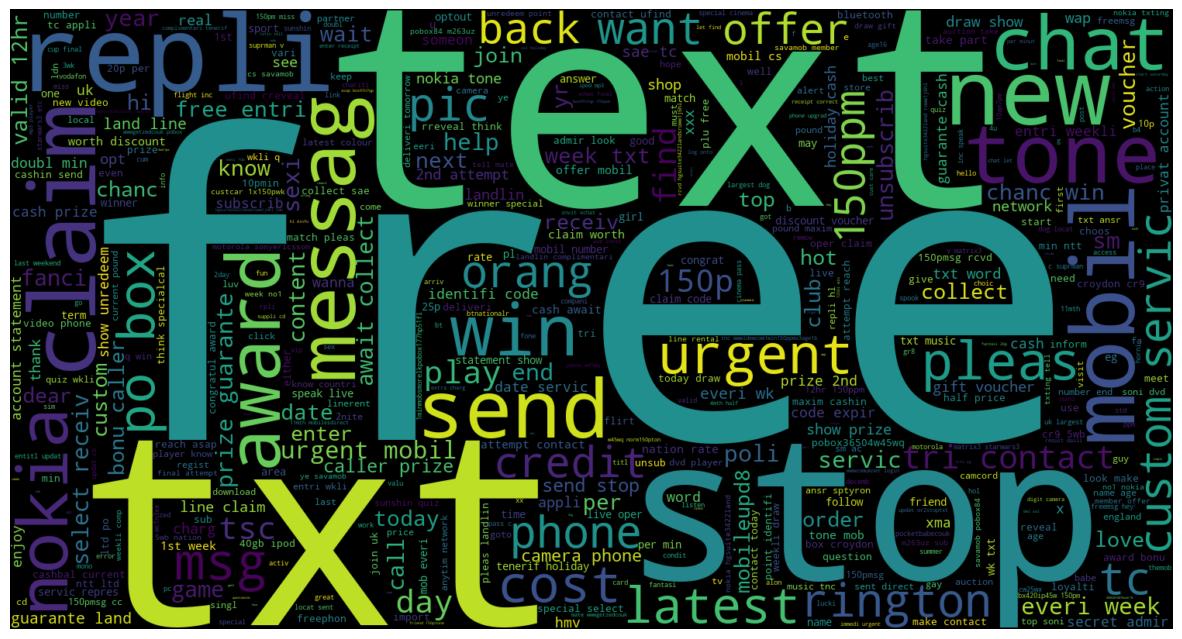

In [277]:
text = " ".join(full_df[full_df['Category'] == 'spam']['Message'])
plt.figure(figsize = (15, 10))
wordcloud = WordCloud(max_words=500, height= 800, width = 1500,  background_color="black", colormap= 'viridis').generate(text)
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

In [279]:
full_df['Category'] = full_df['Category'].replace({'spam':1,'ham':0})

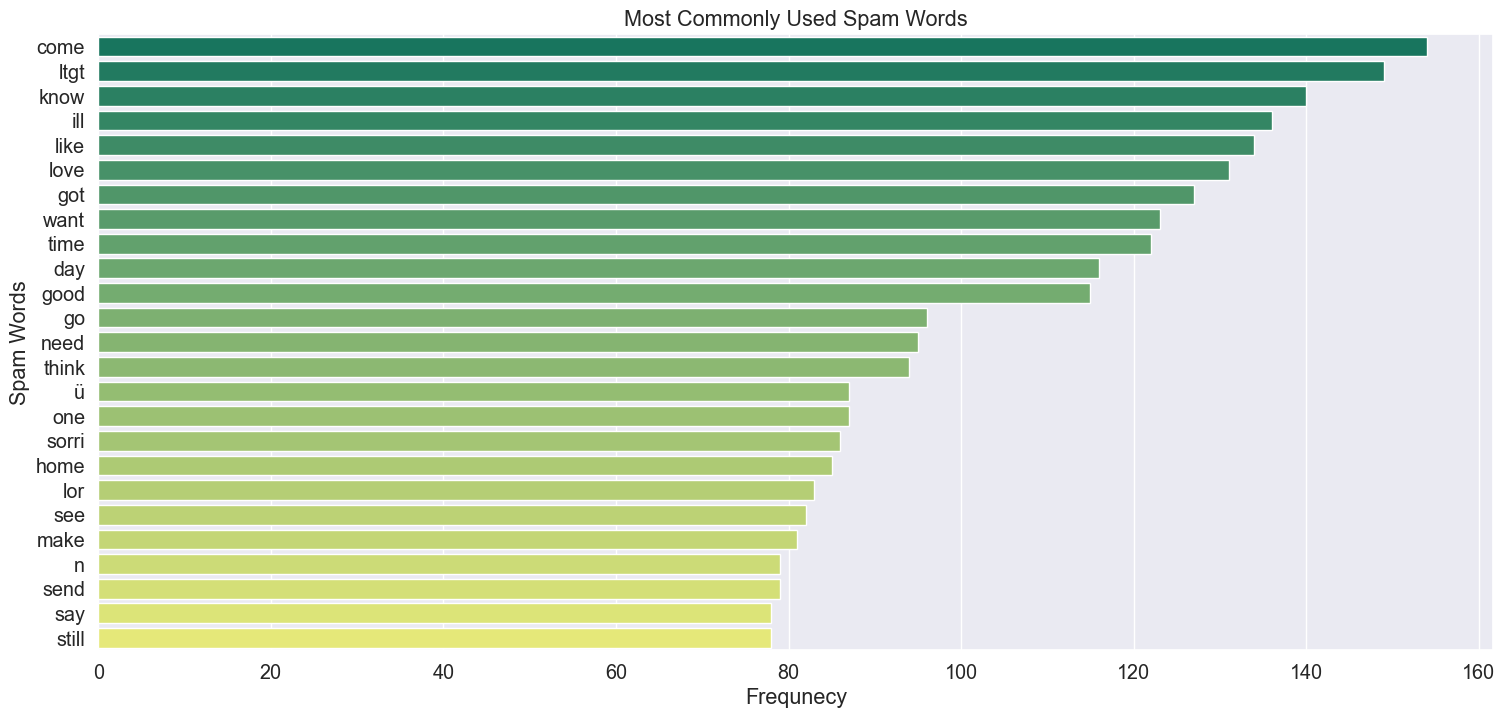

In [281]:
all_spam_words = []
for sentence in full_df[full_df['Category'] == 0]['Message'].to_list():
    for word in sentence.split():
        all_spam_words.append(word)

df = pd.DataFrame(Counter(all_spam_words).most_common(25), columns= ['Word', 'Frequency'])

sns.set_context('notebook', font_scale= 1.3)
plt.figure(figsize=(18,8))
sns.barplot(y = df['Word'], x= df['Frequency'], palette= 'summer')
plt.title("Most Commonly Used Spam Words")
plt.xlabel("Frequnecy")
plt.ylabel("Spam Words")
plt.show()

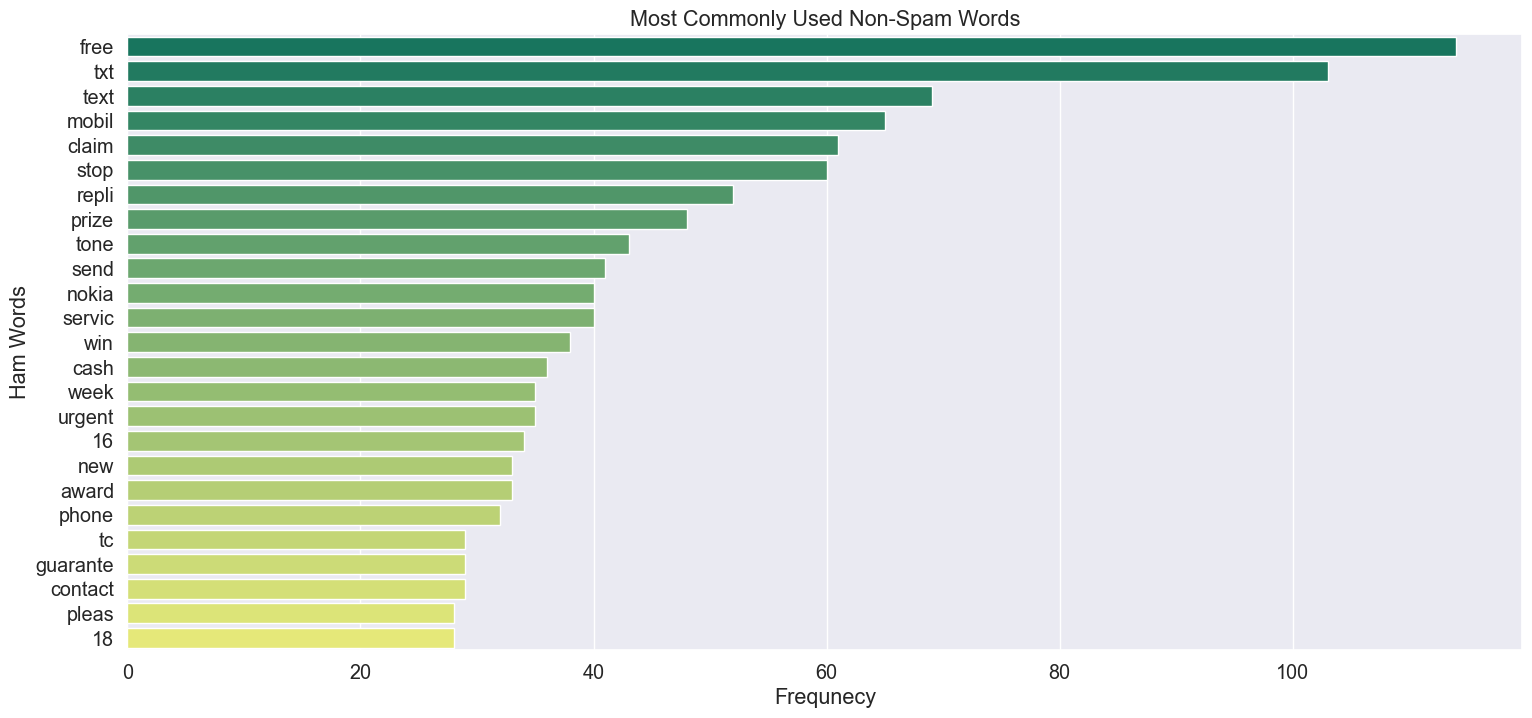

In [283]:
all_ham_words = []
for sentence in full_df[full_df['Category'] == 1]['Message'].to_list():
    for word in sentence.split():
        all_ham_words.append(word)

df = pd.DataFrame(Counter(all_ham_words).most_common(25), columns= ['Word', 'Frequency'])

sns.set_context('notebook', font_scale= 1.3)
plt.figure(figsize=(18,8))
sns.barplot(y = df['Word'], x= df['Frequency'], palette= 'summer')
plt.title("Most Commonly Used Non-Spam Words")
plt.xlabel("Frequnecy")
plt.ylabel("Ham Words")
plt.show()

### TEXT VECTORIZATION

In [285]:
X = full_df["Message"]
y = full_df['Category'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42, stratify = y)

In [287]:
tfidf = TfidfVectorizer(max_features= 2500, min_df= 2)
X_train = tfidf.fit_transform(X_train).toarray()
X_test = tfidf.transform(X_test).toarray()

In [289]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    confusion_matrix,
    roc_curve,
    auc
)

In [291]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    auc,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import seaborn as sns

def train_model(model):
    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = round(accuracy_score(y_test, y_pred), 3)
    precision = round(precision_score(y_test, y_pred, zero_division=0), 3)
    recall = round(recall_score(y_test, y_pred, zero_division=0), 3)
    f1 = round(f1_score(y_test, y_pred, zero_division=0), 3)

    # Print evaluation metrics
    print(f'Accuracy of the model: {accuracy}')
    print(f'Precision Score of the model: {precision}')
    print(f'Recall Score of the model: {recall}')
    print(f'F1 Score of the model: {f1}')

    # Set plot style
    sns.set_context('notebook', font_scale=1.3)

    # Create subplots
    fig, ax = plt.subplots(1, 2, figsize=(20, 7))

    # Plot confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=ax[0], cmap='YlGnBu', colorbar=False)
    ax[0].set_title('Confusion Matrix')

    # Plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    ax[1].plot(
        fpr, tpr,
        label=f'ROC Curve (AUC = {roc_auc:.3f})',
        color='green',
        linewidth=2
    )
    ax[1].plot(
        [0, 1], [0, 1],
        linestyle='--',
        color='gray',
        label='Random Classifier'
    )

    ax[1].set_title('ROC Curve')
    ax[1].set_xlabel('False Positive Rate')
    ax[1].set_ylabel('True Positive Rate')
    ax[1].legend(loc='lower right')
    ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

Accuracy of the model: 0.977
Precision Score of the model: 0.986
Recall Score of the model: 0.841
F1 Score of the model: 0.908


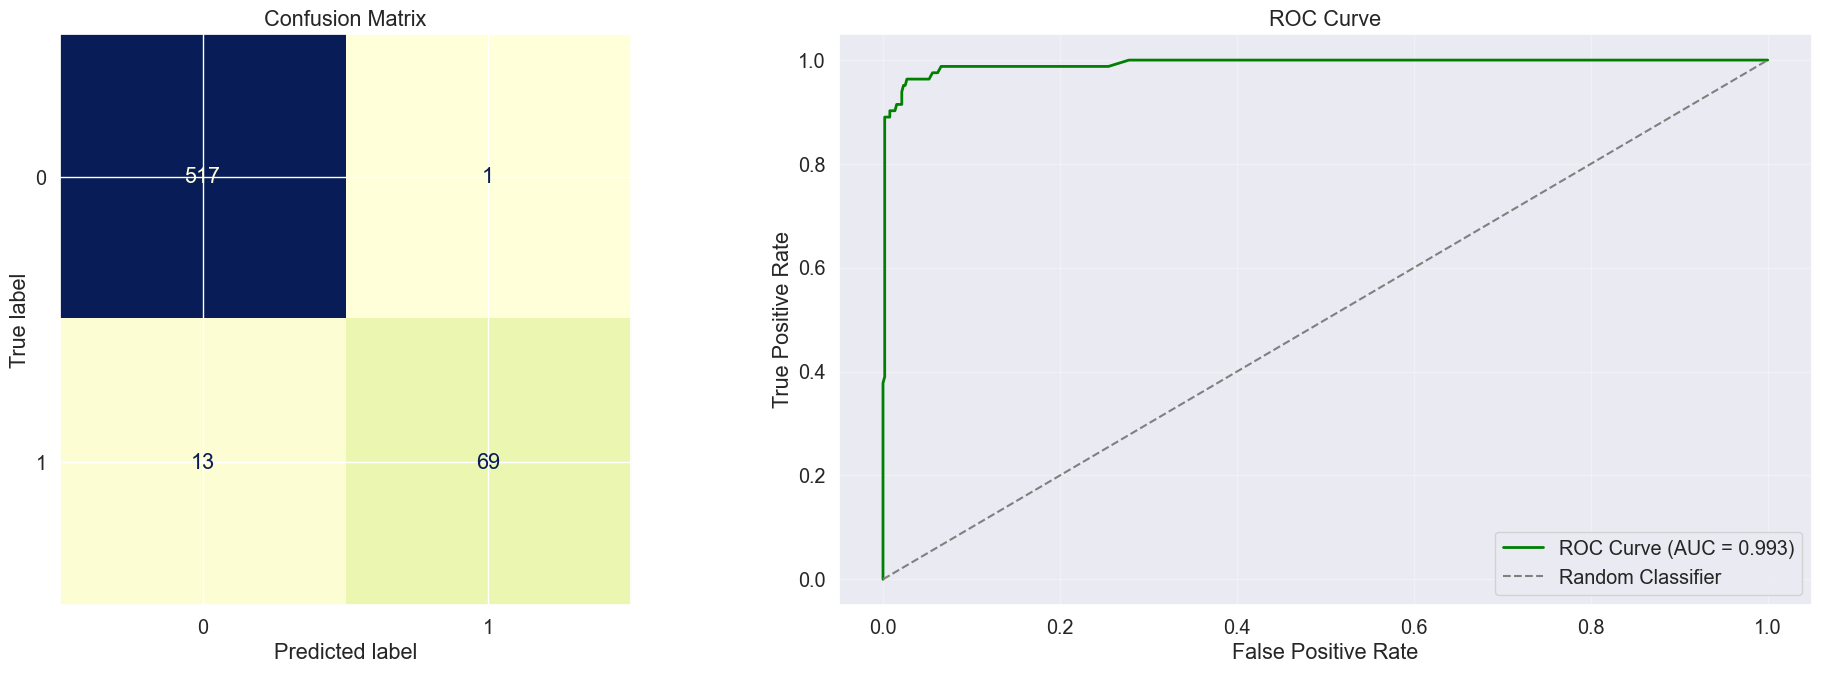

In [322]:
rf = RandomForestClassifier(n_estimators= 300)
train_model(rf)

Accuracy of the model: 0.977
Precision Score of the model: 1.0
Recall Score of the model: 0.829
F1 Score of the model: 0.907


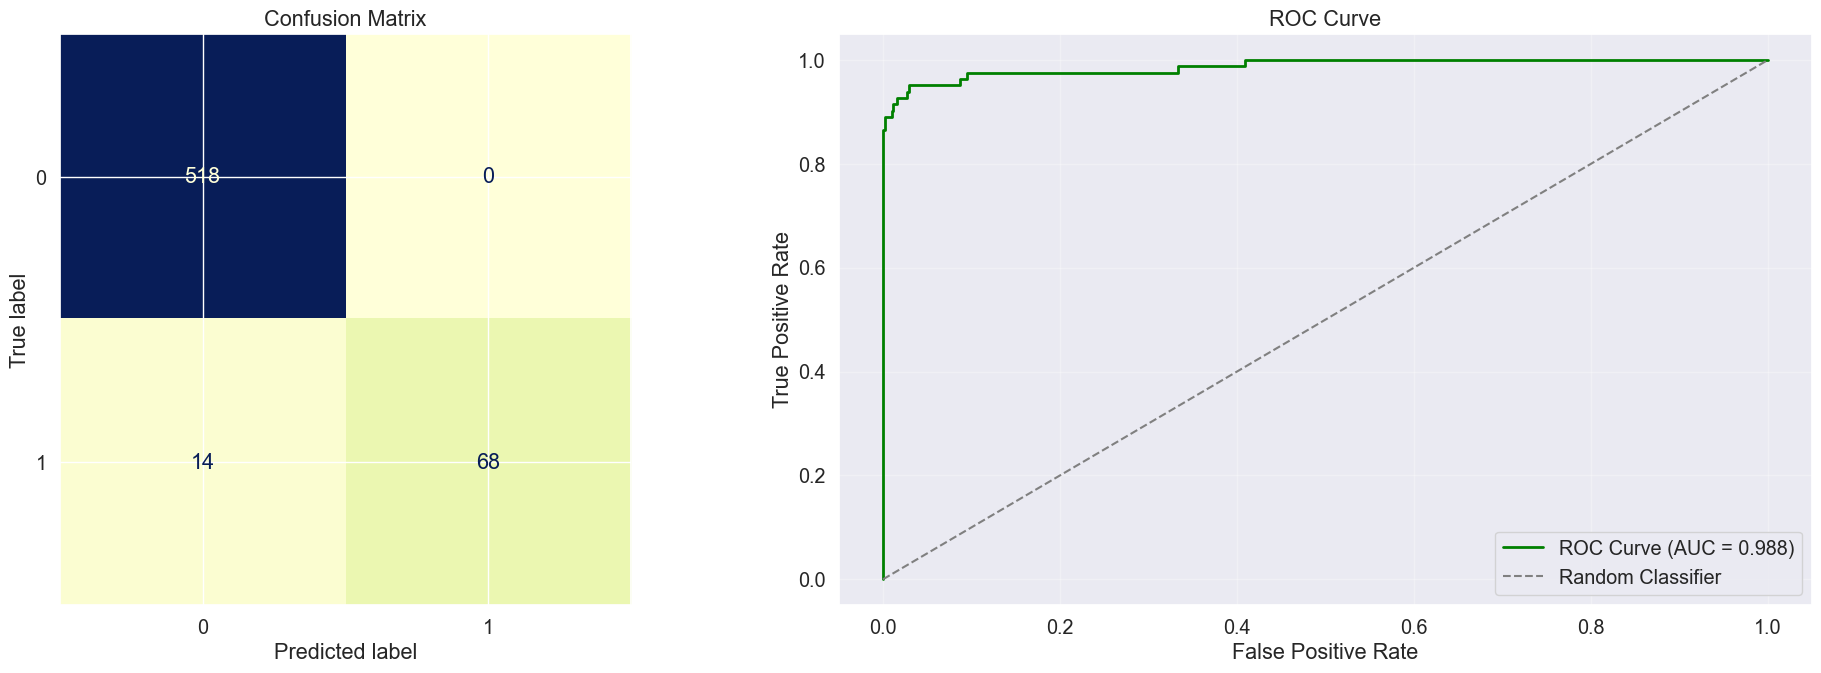

In [217]:
nb_model = MultinomialNB()
nb_model = train_model(nb_model)

In [326]:
def predict_message(message, model, threshold=0.5):
    message_clean = clean_text(message)
    message_tfidf = tfidf.transform([message_clean]).toarray()
    
   
    if message_tfidf.sum() == 0:
        return "🚨 Spam Message (Unknown Words)"
    
    prob = model.predict_proba(message_tfidf)[0]
    spam_prob = prob[1]
    ham_prob = prob[0]

    print(f"Ham Probability : {ham_prob:.2f}")
    print(f"Spam Probability: {spam_prob:.2f}")

    if spam_prob >= threshold:
        return "🚨 Spam Message"
    else:
        return "✅ Ham Message"

In [328]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [342]:
user_input = input("Enter a message: ")
result = predict_message(user_input, nb)
print("Final Prediction:", result)

Enter a message:  Congratulations! You've won a free iPhone. Click here to claim.


Ham Probability : 0.14
Spam Probability: 0.86
Final Prediction: 🚨 Spam Message


In [344]:
message = "Congratulations! You've won a free iPhone. Click here to claim."

cleaned = clean_text(message)
features = tfidf.transform([cleaned])

print("Cleaned message:", cleaned)
print("Known TF-IDF words:", features.nnz)

if features.nnz > 0:
    probabilities = rf.predict_proba(features)[0]

    for label, prob in zip(rf.classes_, probabilities):
        print(f"Class {label}: {prob:.2%}")

Cleaned message: congratul ! 've free iphon . click claim .
Known TF-IDF words: 4
Class 0: 43.33%
Class 1: 56.67%
